# IBM Quantum Level-2 — Final Sweet-Spot Evaluation

This notebook is the **final, reproducible evaluation pipeline** for the hardware experiment:

**Temporal 30-day Sweet-Spot vs 10 topology-valid random controls per backend**

It will:

1. Locate the actual `ibm_circuits` project directory.
2. Load FEZ, Marrakesh, and **both completed Kingston jobs**.
3. If the fresh Kingston result is missing locally, retrieve it from IBM Quantum **without submitting a new job**.
4. Save the collected data into the project folder.
5. Use the **fresh Kingston job as the primary Kingston experiment** and the older Kingston job as a replication.
6. Compute backend-level and circuit-level statistics.
7. Test whether the model-selected Sweet-Spot beats random controls.
8. Quantify shot uncertainty and bootstrap uncertainty.
9. Analyze the transpilation-depth confound.
10. Compare the 1/3/7/30-day temporal models and explicitly explain why 30-day was selected.
11. Generate report-ready CSVs, JSON, PNG figures, and a final conclusion.

**Important:** this notebook never calls `SamplerV2.run()` and therefore never submits a new QPU job.


In [1]:

# ============================================================
# 0. ROBUST PROJECT-DIRECTORY DETECTION
# ============================================================
from pathlib import Path
import os, json, math, warnings, re, sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

KNOWN_PROJECT = Path(r"D:\Downloads\uday projects\ibm_circuits")

def looks_like_project(p: Path) -> bool:
    return (
        p.exists()
        and (
            (p / "run_level1.py").exists()
            or (p / "select_level2_candidates.py").exists()
            or (p / "results").exists()
            or (p / "sweet_spot_level2_candidates.csv").exists()
        )
    )

candidates = []

# 1) Explicit environment override.
if os.environ.get("IBM_CIRCUITS_PROJECT_ROOT"):
    candidates.append(Path(os.environ["IBM_CIRCUITS_PROJECT_ROOT"]))

# 2) The user's known local project path.
candidates.append(KNOWN_PROJECT)

# 3) Current directory and its parents.
cwd = Path.cwd().resolve()
candidates.extend([cwd] + list(cwd.parents))

# 4) If the notebook was opened from a project subdirectory.
for base in [cwd, *cwd.parents]:
    candidates.append(base / "ibm_circuits")

PROJECT_ROOT = next((p.resolve() for p in candidates if looks_like_project(p)), None)

if PROJECT_ROOT is None:
    # Last-resort: use the current directory and make the output visible there.
    PROJECT_ROOT = cwd

RESULTS_DIR = PROJECT_ROOT / "results"
EVAL_DIR = PROJECT_ROOT / "sweet_spot_evaluation"
RESULTS_EVAL_DIR = RESULTS_DIR / "sweet_spot_evaluation"

EVAL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_EVAL_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("PROJECT ROOT:", PROJECT_ROOT)
print("VISIBLE OUTPUT:", EVAL_DIR)
print("RESULTS OUTPUT:", RESULTS_EVAL_DIR)
print("=" * 80)
print("If PROJECT ROOT above is not your ibm_circuits folder, set")
print("IBM_CIRCUITS_PROJECT_ROOT before running the notebook.")


PROJECT ROOT: D:\Downloads\uday projects\ibm_circuits
VISIBLE OUTPUT: D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation
RESULTS OUTPUT: D:\Downloads\uday projects\ibm_circuits\results\sweet_spot_evaluation
If PROJECT ROOT above is not your ibm_circuits folder, set
IBM_CIRCUITS_PROJECT_ROOT before running the notebook.


## 1. Experiment definition

The final selector used the **Temporal 30-day model**, prediction date **2026-09-06**, and selected the highest-scoring topology-valid physical 3-qubit chain per backend. Ten random controls were sampled without overlap with the Sweet-Spot or with one another. The candidate manifest records these constraints. fileciteturn81file5L5-L10

The final experiment used 256 shots and 11 circuits per backend. fileciteturn81file1L5-L12


In [2]:

# ============================================================
# 2. FIXED EXPERIMENT/JOB IDENTIFIERS
# ============================================================
PREDICTION_DATE = "2026-09-06"
SHOTS = 256
EXPECTED_CIRCUITS = 11

JOB_IDS = {
    "ibm_fez": ["dafgfb5nj4cs73agbfo0"],
    "ibm_kingston": [
        "dafgfgl1ierc738nbdd0",  # older completed Kingston job
        "dafpntd1ierc738nnmpg",  # fresh Kingston job — primary
    ],
    "ibm_marrakesh": ["dafpe83dd5gc73da62o0"],
}

PRIMARY_KINGSTON_JOB = "dafpntd1ierc738nnmpg"
OLD_KINGSTON_JOB = "dafgfgl1ierc738nbdd0"

print(json.dumps(JOB_IDS, indent=2))


{
  "ibm_fez": [
    "dafgfb5nj4cs73agbfo0"
  ],
  "ibm_kingston": [
    "dafgfgl1ierc738nbdd0",
    "dafpntd1ierc738nnmpg"
  ],
  "ibm_marrakesh": [
    "dafpe83dd5gc73da62o0"
  ]
}


## 3. Local result-file collection

The previous notebook's main failure was path selection: it could execute correctly while writing to the notebook kernel's `/mnt/data` environment instead of the user's actual `ibm_circuits` project.

This version writes to **both**:

- `ibm_circuits/sweet_spot_evaluation/`
- `ibm_circuits/results/sweet_spot_evaluation/`

So the generated artifacts are visible directly in the project folder and also under `results/`.


In [3]:

# ============================================================
# 4. FIND LOCAL RESULT FILES
# ============================================================
def local_result_candidates(backend):
    return [
        RESULTS_DIR / f"sweet_spot_level2_ibm_{backend.replace('ibm_', '')}_result.json",
        PROJECT_ROOT / f"sweet_spot_level2_ibm_{backend.replace('ibm_', '')}_result.json",
        RESULTS_DIR / f"sweet_spot_level2_{backend}_result.json",
        PROJECT_ROOT / f"sweet_spot_level2_{backend}_result.json",
    ]

def find_valid_local_result(backend, desired_job_ids=None):
    desired_job_ids = set(map(str, desired_job_ids or []))
    found = []
    for p in local_result_candidates(backend):
        if p.exists():
            try:
                payload = json.loads(p.read_text(encoding="utf-8"))
                jid = str(payload.get("job_id", ""))
                found.append((p, jid, payload))
            except Exception as e:
                print("Could not read", p, ":", e)

    # Prefer a result whose job_id is explicitly one of the requested jobs.
    for p, jid, payload in found:
        if jid in desired_job_ids:
            return p, jid, payload

    return (found[0] if found else (None, None, None))

for backend, ids in JOB_IDS.items():
    p, jid, _ = find_valid_local_result(backend, ids)
    print(f"{backend:16s} -> {p} | job_id={jid}")


ibm_fez          -> D:\Downloads\uday projects\ibm_circuits\results\sweet_spot_level2_ibm_fez_result.json | job_id=dafgfb5nj4cs73agbfo0
ibm_kingston     -> D:\Downloads\uday projects\ibm_circuits\results\sweet_spot_level2_ibm_kingston_result.json | job_id=dafgfgl1ierc738nbdd0
ibm_marrakesh    -> D:\Downloads\uday projects\ibm_circuits\results\sweet_spot_level2_ibm_marrakesh_result.json | job_id=dafpe83dd5gc73da62o0


## 4. Automatic IBM recovery — only when necessary

The fresh Kingston job is:

`dafpntd1ierc738nnmpg`

If its result is not present locally, this cell attempts to retrieve the already-completed job using `QiskitRuntimeService.job(job_id)`. It **does not submit anything**.

If credentials are unavailable, the notebook continues with the locally available data and clearly marks the fresh Kingston result as missing instead of inventing it.


In [4]:

# ============================================================
# 5. SAFE IBM RECOVERY OF MISSING COMPLETED JOBS
# ============================================================
def extract_counts(pub_result):
    data = pub_result.data
    if hasattr(data, "c") and hasattr(data.c, "get_counts"):
        return {str(k): int(v) for k, v in data.c.get_counts().items()}

    for name in dir(data):
        if name.startswith("_"):
            continue
        try:
            obj = getattr(data, name)
            if hasattr(obj, "get_counts"):
                return {str(k): int(v) for k, v in obj.get_counts().items()}
        except Exception:
            pass

    raise RuntimeError("Could not extract measurement counts from SamplerV2 result.")

def ghz_fidelity(counts):
    total = sum(int(v) for v in counts.values())
    if total <= 0:
        raise ValueError("No shots found.")
    return (int(counts.get("000", 0)) + int(counts.get("111", 0))) / total

def recover_completed_job(backend_name, job_id):
    from dotenv import load_dotenv
    load_dotenv(PROJECT_ROOT / ".env", override=False)

    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService()

    job = service.job(job_id)
    status = str(job.status()).upper()
    print(f"{backend_name}: {job_id} -> {status}")

    if status not in {"DONE", "COMPLETED"}:
        raise RuntimeError(f"Job {job_id} is not completed; status={status}")

    result = job.result()
    if len(result) != EXPECTED_CIRCUITS:
        raise RuntimeError(
            f"Expected {EXPECTED_CIRCUITS} PUB results, got {len(result)}"
        )

    rows = []
    for i in range(len(result)):
        counts = extract_counts(result[i])
        rows.append({
            "circuit_index": i,
            "counts": counts,
            "ghz_fidelity": ghz_fidelity(counts),
        })

    try:
        usage = float(job.usage(partial=False))
    except Exception:
        usage = None

    try:
        creation_date = str(job.creation_date)
    except Exception:
        creation_date = None

    payload = {
        "experiment": "sweet_spot_vs_random",
        "level": 2,
        "backend": backend_name,
        "job_id": job_id,
        "shots": SHOTS,
        "qpu_usage_seconds": usage,
        "creation_date": creation_date,
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "results": [
            {
                "backend": backend_name,
                "circuit_index": r["circuit_index"],
                "group": "unknown",
                "trial": r["circuit_index"],
                "model": "unknown",
                "physical_qubits": [],
                "mean_viability": None,
                "shots": SHOTS,
                "job_id": job_id,
                "counts": r["counts"],
                "ghz_fidelity": r["ghz_fidelity"],
                "transpiled_depth": None,
            }
            for r in rows
        ],
    }

    # Keep a raw recovery copy with an unambiguous job ID.
    raw_path = EVAL_DIR / f"{backend_name}_{job_id}_raw_retrieved.json"
    raw_path.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    RESULTS_EVAL_DIR.joinpath(raw_path.name).write_text(
        raw_path.read_text(encoding="utf-8"), encoding="utf-8"
    )

    print("Recovered and saved:", raw_path)
    return payload

def payload_has_job(path, job_id):
    if path is None or not path.exists():
        return False
    try:
        return str(json.loads(path.read_text(encoding="utf-8")).get("job_id")) == str(job_id)
    except Exception:
        return False

# Recover the fresh Kingston job if the local primary result is absent.
fresh_local = None
for p in [
    RESULTS_DIR / "sweet_spot_level2_ibm_kingston_result.json",
    PROJECT_ROOT / "sweet_spot_level2_ibm_kingston_result.json",
]:
    if payload_has_job(p, PRIMARY_KINGSTON_JOB):
        fresh_local = p
        break

if fresh_local:
    print("Fresh Kingston result already exists:", fresh_local)
else:
    print("Fresh Kingston result not found locally.")
    try:
        fresh_payload = recover_completed_job("ibm_kingston", PRIMARY_KINGSTON_JOB)
        # Save a canonical per-backend result in the project.
        canonical = RESULTS_DIR / "sweet_spot_level2_ibm_kingston_fresh_result.json"
        canonical.write_text(json.dumps(fresh_payload, indent=2), encoding="utf-8")
        print("Canonical fresh Kingston result:", canonical)
    except Exception as exc:
        print("\nWARNING: Could not automatically recover fresh Kingston.")
        print(type(exc).__name__ + ":", exc)
        print("The notebook will continue with any local completed Kingston result.")


Fresh Kingston result not found locally.

AccountNotFoundError: "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."
The notebook will continue with any local completed Kingston result.


In [5]:

# ============================================================
# 6. LOAD ALL AVAILABLE HARDWARE JSONS
# ============================================================
def load_json(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))

def discover_backend_payloads(backend):
    candidates = []

    # Canonical files.
    candidates.extend(local_result_candidates(backend))

    # Fresh Kingston canonical recovery file.
    if backend == "ibm_kingston":
        candidates.append(RESULTS_DIR / "sweet_spot_level2_ibm_kingston_fresh_result.json")

    # Raw recovery files.
    candidates.extend(sorted(EVAL_DIR.glob(f"{backend}_*_raw_retrieved.json")))
    candidates.extend(sorted(RESULTS_EVAL_DIR.glob(f"{backend}_*_raw_retrieved.json")))

    seen = set()
    payloads = []
    for p in candidates:
        p = Path(p)
        if not p.exists() or str(p.resolve()) in seen:
            continue
        seen.add(str(p.resolve()))
        try:
            payload = load_json(p)
            jid = str(payload.get("job_id", ""))
            if jid:
                payloads.append((jid, p, payload))
        except Exception as e:
            print("Skipping unreadable", p, ":", e)

    # Deduplicate by job ID, preferring the newest file encountered.
    by_job = {}
    for jid, p, payload in payloads:
        by_job[jid] = (p, payload)
    return [(jid, *by_job[jid]) for jid in by_job]

all_payloads = []
for backend in ["ibm_fez", "ibm_kingston", "ibm_marrakesh"]:
    items = discover_backend_payloads(backend)
    for jid, p, payload in items:
        all_payloads.append((backend, jid, p, payload))
        print(f"{backend:16s} {jid:22s} <- {p}")

print("\nUnique completed payloads loaded:", len(all_payloads))


ibm_fez          dafgfb5nj4cs73agbfo0   <- D:\Downloads\uday projects\ibm_circuits\results\sweet_spot_level2_ibm_fez_result.json
ibm_kingston     dafgfgl1ierc738nbdd0   <- D:\Downloads\uday projects\ibm_circuits\results\sweet_spot_level2_ibm_kingston_result.json
ibm_marrakesh    dafpe83dd5gc73da62o0   <- D:\Downloads\uday projects\ibm_circuits\results\sweet_spot_level2_ibm_marrakesh_result.json

Unique completed payloads loaded: 3


## 5. Attach the exact experimental candidate metadata

The candidate manifest defines the final Sweet-Spot and controls. The hardware result files contain measured counts/fidelity and, in the normal runner output, also contain physical-qubit and depth metadata.

The final selected chains were:

- FEZ: `[13, 14, 15]`
- Kingston: `[149, 150, 151]`
- Marrakesh: `[132, 133, 134]`

The candidate manifest records the corresponding model viability scores. fileciteturn81file5L14-L30 fileciteturn81file5L117-L134 fileciteturn81file5L220-L236


In [6]:

# ============================================================
# 7. NORMALIZE HARDWARE PAYLOADS
# ============================================================
hardware_rows = []

for backend, jid, path, payload in all_payloads:
    if isinstance(payload.get("results"), list):
        for r in payload["results"]:
            rr = dict(r)
            rr["backend"] = rr.get("backend", backend)
            rr["job_id"] = str(rr.get("job_id", jid))
            if "ghz_fidelity" not in rr and "counts" in rr:
                rr["ghz_fidelity"] = ghz_fidelity(rr["counts"])
            hardware_rows.append(rr)

hardware = pd.DataFrame(hardware_rows)

if hardware.empty:
    raise RuntimeError("No hardware results could be loaded.")

hardware["job_id"] = hardware["job_id"].astype(str)
hardware["ghz_fidelity"] = pd.to_numeric(hardware["ghz_fidelity"], errors="coerce")
hardware["transpiled_depth"] = pd.to_numeric(hardware.get("transpiled_depth"), errors="coerce")

print("Loaded hardware rows:", len(hardware))
display(
    hardware[
        ["backend", "job_id", "circuit_index", "group",
         "trial", "physical_qubits", "ghz_fidelity", "transpiled_depth"]
    ].sort_values(["backend", "job_id", "circuit_index"])
)


Loaded hardware rows: 33


,backend,job_id,circuit_index,group,trial,physical_qubits,ghz_fidelity,transpiled_depth
0,ibm_fez,dafgfb5nj4cs73agbfo0,0,sweet_spot,0,"[13, 14, 15]",0.941406,12
1,ibm_fez,dafgfb5nj4cs73agbfo0,1,random_control,1,"[63, 64, 65]",0.808594,12
2,ibm_fez,dafgfb5nj4cs73agbfo0,2,random_control,2,"[82, 83, 96]",0.753906,12
3,ibm_fez,dafgfb5nj4cs73agbfo0,3,random_control,3,"[109, 118, 129]",0.945312,12
4,ibm_fez,dafgfb5nj4cs73agbfo0,4,random_control,4,"[104, 105, 106]",0.976562,12
5,ibm_fez,dafgfb5nj4cs73agbfo0,5,random_control,5,"[100, 101, 102]",0.812500,12
6,ibm_fez,dafgfb5nj4cs73agbfo0,6,random_control,6,"[60, 61, 62]",0.867188,12
7,ibm_fez,dafgfb5nj4cs73agbfo0,7,random_control,7,"[91, 92, 98]",0.941406,18
8,ibm_fez,dafgfb5nj4cs73agbfo0,8,random_control,8,"[24, 25, 26]",0.917969,12
9,ibm_fez,dafgfb5nj4cs73agbfo0,9,random_control,9,"[67, 68, 69]",0.921875,12


In [7]:

# ============================================================
# 8. FILL METADATA FROM THE CANDIDATE MANIFEST WHEN NEEDED
# ============================================================
candidate_paths = [
    RESULTS_DIR / "sweet_spot_level2_candidates.json",
    PROJECT_ROOT / "sweet_spot_level2_candidates.json",
]
candidate_path = next((p for p in candidate_paths if p.exists()), None)

if candidate_path is None:
    print("Candidate JSON not found locally; using the recorded final candidate manifest.")
    candidate_manifest = {
        "ibm_fez": {
            "sweet_spot": [13,14,15],
            "sweet_viability": 0.9211304416488967,
            "controls": [[63,64,65],[82,83,96],[109,118,129],[104,105,106],
                         [100,101,102],[60,61,62],[91,92,98],[24,25,26],
                         [67,68,69],[55,59,75]]
        },
        "ibm_kingston": {
            "sweet_spot": [149,150,151],
            "sweet_viability": 0.9606234740730591,
            "controls": [[141,142,143],[22,23,24],[15,19,35],[91,98,111],
                         [86,87,88],[123,124,136],[109,118,129],[112,113,114],
                         [83,84,85],[25,37,45]]
        },
        "ibm_marrakesh": {
            "sweet_spot": [132,133,134],
            "sweet_viability": 0.9270971906677378,
            "controls": [[53,54,55],[111,112,113],[145,146,147],[51,58,71],
                         [88,89,90],[33,34,39],[10,11,18],[25,37,45],
                         [130,131,138],[107,108,109]]
        },
    }
else:
    candidate_manifest = load_json(candidate_path)

def manifest_backend_info(manifest, backend):
    # Supports both {backends:[...]} and {backend:{...}} structures.
    if isinstance(manifest.get("backends"), list):
        for b in manifest["backends"]:
            if b.get("backend") == backend:
                return b
    if backend in manifest:
        return manifest[backend]
    return None

for backend in ["ibm_fez", "ibm_kingston", "ibm_marrakesh"]:
    info = manifest_backend_info(candidate_manifest, backend)
    print(backend, "manifest found:", info is not None)


ibm_fez manifest found: True
ibm_kingston manifest found: True
ibm_marrakesh manifest found: True


In [8]:

# ============================================================
# 9. COMPLETE/FIX GROUP + QUANTUM METADATA
# ============================================================
def normalize_qubits(x):
    if isinstance(x, str):
        try:
            x = json.loads(x)
        except Exception:
            nums = re.findall(r"\d+", x)
            x = [int(v) for v in nums]
    if isinstance(x, (list, tuple)):
        return [int(v) for v in x]
    return []

records = []
for _, r in hardware.iterrows():
    rr = r.to_dict()
    backend = rr["backend"]
    idx = int(rr["circuit_index"])
    info = manifest_backend_info(candidate_manifest, backend)

    qubits = normalize_qubits(rr.get("physical_qubits"))
    if not qubits and info:
        sweet = info.get("sweet_spot", {})
        if isinstance(sweet, dict):
            sweet_q = sweet.get("qubits", [])
            controls = info.get("random_controls", [])
        else:
            sweet_q = sweet
            controls = info.get("controls", [])

        if idx == 0:
            qubits = list(map(int, sweet_q))
        elif idx <= len(controls):
            c = controls[idx-1]
            qubits = list(map(int, c.get("qubits", c) if isinstance(c, dict) else c))

    group = rr.get("group")
    if group not in {"sweet_spot", "random_control"}:
        group = "sweet_spot" if idx == 0 else "random_control"

    rr["group"] = group
    rr["is_sweet_spot"] = group == "sweet_spot"
    rr["physical_qubits"] = qubits
    rr["model"] = rr.get("model") or ("temporal_30day" if rr["is_sweet_spot"] else "random")
    rr["shots"] = int(rr.get("shots") or SHOTS)
    records.append(rr)

hardware = pd.DataFrame(records)

# Candidate viability only belongs to the Sweet-Spot, not random controls.
for backend in hardware["backend"].unique():
    info = manifest_backend_info(candidate_manifest, backend)
    viability = np.nan
    if info:
        sv = info.get("sweet_spot", {})
        viability = sv.get("mean_viability") if isinstance(sv, dict) else info.get("sweet_viability")
    mask = (hardware["backend"] == backend) & hardware["is_sweet_spot"]
    hardware.loc[mask, "mean_viability"] = viability

print("Normalized rows:", len(hardware))


Normalized rows: 33


# 6. Primary experiment dataset

**Primary Kingston = fresh job `dafpntd1ierc738nnmpg`.**

The older Kingston job `dafgfgl1ierc738nbdd0` is retained separately as a replication/repeatability experiment.

This is critical: the two Kingston jobs are not counted as two independent backends.


In [9]:

# ============================================================
# 10. SELECT PRIMARY VS REPLICATION
# ============================================================
primary_job = {
    "ibm_fez": "dafgfb5nj4cs73agbfo0",
    "ibm_marrakesh": "dafpe83dd5gc73da62o0",
    "ibm_kingston": PRIMARY_KINGSTON_JOB,
}

replication_job = {
    "ibm_kingston": OLD_KINGSTON_JOB,
}

primary_parts = []
missing_primary = []

for backend, jid in primary_job.items():
    part = hardware[
        (hardware["backend"] == backend) &
        (hardware["job_id"].astype(str) == str(jid))
    ].copy()
    if part.empty:
        missing_primary.append((backend, jid))
    else:
        primary_parts.append(part)

if missing_primary:
    print("WARNING — primary jobs missing:", missing_primary)
    print("If the fresh Kingston job is missing, rerun the IBM recovery cell.")

primary = pd.concat(primary_parts, ignore_index=True) if primary_parts else pd.DataFrame()

replication = hardware[
    (hardware["backend"] == "ibm_kingston") &
    (hardware["job_id"].astype(str) == OLD_KINGSTON_JOB)
].copy()

print("Primary rows:", len(primary))
print("Kingston replication rows:", len(replication))

display(primary[["backend","job_id","group","trial","physical_qubits","ghz_fidelity","transpiled_depth"]])


WARNING — primary jobs missing: [('ibm_kingston', 'dafpntd1ierc738nnmpg')]
If the fresh Kingston job is missing, rerun the IBM recovery cell.
Primary rows: 22
Kingston replication rows: 11


,backend,job_id,group,trial,physical_qubits,ghz_fidelity,transpiled_depth
0,ibm_fez,dafgfb5nj4cs73agbfo0,sweet_spot,0,"[13, 14, 15]",0.941406,12
1,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,1,"[63, 64, 65]",0.808594,12
2,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,2,"[82, 83, 96]",0.753906,12
3,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,3,"[109, 118, 129]",0.945312,12
4,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,4,"[104, 105, 106]",0.976562,12
5,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,5,"[100, 101, 102]",0.812500,12
6,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,6,"[60, 61, 62]",0.867188,12
7,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,7,"[91, 92, 98]",0.941406,18
8,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,8,"[24, 25, 26]",0.917969,12
9,ibm_fez,dafgfb5nj4cs73agbfo0,random_control,9,"[67, 68, 69]",0.921875,12


In [10]:

# ============================================================
# 11. HARD VALIDATION
# ============================================================
if not primary.empty:
    for backend, g in primary.groupby("backend"):
        assert len(g) == EXPECTED_CIRCUITS, f"{backend}: expected 11 circuits, got {len(g)}"
        assert g["ghz_fidelity"].between(0, 1).all(), f"{backend}: invalid fidelity"
        assert g["shots"].eq(SHOTS).all(), f"{backend}: unexpected shot count"
        assert g["is_sweet_spot"].sum() == 1, f"{backend}: expected one Sweet-Spot"
        assert (~g["is_sweet_spot"]).sum() == 10, f"{backend}: expected ten controls"
    print("PRIMARY DATA VALIDATION: PASS")
else:
    print("PRIMARY DATA VALIDATION: NOT RUN — primary dataset incomplete.")


PRIMARY DATA VALIDATION: PASS


# 7. Core hardware evaluation

The central endpoint is GHZ fidelity:

`F_GHZ = [N(000) + N(111)] / N_total`

The test is **not** whether the Sweet-Spot has the highest absolute fidelity among all qubits on Earth. It is whether the model-selected physical chain systematically outperforms the topology-valid random controls selected on the same backend.


In [11]:

# ============================================================
# 12. BACKEND SUMMARY
# ============================================================
summary_rows = []

for backend, g in primary.groupby("backend"):
    sweet = float(g.loc[g["is_sweet_spot"], "ghz_fidelity"].iloc[0])
    controls = g.loc[~g["is_sweet_spot"], "ghz_fidelity"].astype(float).to_numpy()

    rank = 1 + int(np.sum(controls > sweet))
    beaten = int(np.sum(sweet > controls))
    ties = int(np.sum(np.isclose(sweet, controls)))

    summary_rows.append({
        "backend": backend,
        "sweet_fidelity": sweet,
        "random_mean": float(np.mean(controls)),
        "random_median": float(np.median(controls)),
        "random_std": float(np.std(controls, ddof=1)),
        "absolute_advantage": sweet - float(np.mean(controls)),
        "percent_advantage": 100 * (sweet / float(np.mean(controls)) - 1),
        "rank_1_best": rank,
        "controls_beaten": beaten,
        "controls_total": len(controls),
        "fraction_controls_beaten": beaten / len(controls),
        "ties": ties,
        "sweet_depth": float(g.loc[g["is_sweet_spot"], "transpiled_depth"].iloc[0]),
        "random_median_depth": float(g.loc[~g["is_sweet_spot"], "transpiled_depth"].median()),
        "predicted_mean_viability": float(g.loc[g["is_sweet_spot"], "mean_viability"].iloc[0]),
    })

backend_summary = pd.DataFrame(summary_rows)

display(backend_summary.round(6))


,backend,sweet_fidelity,random_mean,random_median,random_std,absolute_advantage,percent_advantage,rank_1_best,controls_beaten,controls_total,fraction_controls_beaten,ties,sweet_depth,random_median_depth,predicted_mean_viability
0,ibm_fez,0.941406,0.884375,0.908203,0.071820,0.057031,6.448763,3,7,10,0.7,1,12.0,12.0,0.921130
1,ibm_marrakesh,0.937500,0.876172,0.914062,0.132506,0.061328,6.999554,5,6,10,0.6,0,12.0,12.0,0.927097


In [12]:

# ============================================================
# 13. POOLED / PAIRED EFFECTS
# ============================================================
if not backend_summary.empty:
    weighted_random_mean = float(
        primary.loc[~primary["is_sweet_spot"], "ghz_fidelity"].mean()
    )
    pooled_sweet_mean = float(
        primary.loc[primary["is_sweet_spot"], "ghz_fidelity"].mean()
    )

    paired_advantages = backend_summary["absolute_advantage"].to_numpy()

    pooled_summary = pd.DataFrame([{
        "backend_count": len(backend_summary),
        "sweet_mean_across_backends": pooled_sweet_mean,
        "random_mean_across_all_controls": weighted_random_mean,
        "pooled_absolute_advantage": pooled_sweet_mean - weighted_random_mean,
        "pooled_percent_advantage": 100 * (pooled_sweet_mean / weighted_random_mean - 1),
        "backend_advantage_mean": float(np.mean(paired_advantages)),
        "backend_advantage_median": float(np.median(paired_advantages)),
        "all_backends_positive": bool(np.all(paired_advantages > 0)),
    }])

    display(pooled_summary.round(6))


,backend_count,sweet_mean_across_backends,random_mean_across_all_controls,pooled_absolute_advantage,pooled_percent_advantage,backend_advantage_mean,backend_advantage_median,all_backends_positive
0,2,0.939453,0.880273,0.05918,6.722876,0.05918,0.05918,True


# 8. Statistical evidence

Because there are only **three independent backends**, the analysis must not pretend there are 33 independent hardware observations.

We therefore report:

- within-backend control distribution;
- paired backend advantages;
- exact sign/permutation evidence across the 3 backend blocks;
- an empirical control-rank test;
- bootstrap intervals as descriptive uncertainty;
- binomial shot uncertainty for each circuit.

These are complementary, not interchangeable.


In [13]:

# ============================================================
# 14. EXACT BACKEND SIGN/PERMUTATION TEST
# ============================================================
if not backend_summary.empty:
    diffs = backend_summary["absolute_advantage"].to_numpy()
    positive = int(np.sum(diffs > 0))

    # Under a null where the selected label is exchangeable with one
    # randomly chosen control at each backend, the sign of each
    # backend-level difference is equally likely to be +/-.
    from itertools import product
    signs = np.array([
        np.sum(np.array(s) * np.abs(diffs) >= np.sum(diffs))
        for s in product([-1, 1], repeat=len(diffs))
    ])
    # More directly: probability all 3 observed differences are positive.
    exact_all_positive_p = 1 / (2 ** len(diffs))

    sign_p_two_sided = 2 * min(
        stats.binomtest(positive, len(diffs), 0.5, alternative="greater").pvalue,
        stats.binomtest(positive, len(diffs), 0.5, alternative="less").pvalue,
    )
    sign_p_two_sided = min(1.0, sign_p_two_sided)

    sign_test = pd.DataFrame([{
        "independent_backends": len(diffs),
        "positive_backend_advantages": positive,
        "all_three_positive_p_one_sided": exact_all_positive_p,
        "sign_test_two_sided_p": sign_p_two_sided,
    }])
    display(sign_test)


,independent_backends,positive_backend_advantages,all_three_positive_p_one_sided,sign_test_two_sided_p
0,2,2,0.25,0.5


In [14]:

# ============================================================
# 15. EMPIRICAL CONTROL TEST
# ============================================================
empirical_rows = []
for backend, g in primary.groupby("backend"):
    sweet = float(g.loc[g["is_sweet_spot"], "ghz_fidelity"].iloc[0])
    controls = g.loc[~g["is_sweet_spot"], "ghz_fidelity"].to_numpy()

    empirical_rows.append({
        "backend": backend,
        "sweet_fidelity": sweet,
        "controls": len(controls),
        "controls_below_sweet": int(np.sum(controls < sweet)),
        "fraction_below": float(np.mean(controls < sweet)),
        "empirical_one_sided_rank_p": float((1 + np.sum(controls >= sweet)) / (len(controls) + 1)),
    })

empirical_control_test = pd.DataFrame(empirical_rows)
display(empirical_control_test)


,backend,sweet_fidelity,controls,controls_below_sweet,fraction_below,empirical_one_sided_rank_p
0,ibm_fez,0.941406,10,7,0.7,0.363636
1,ibm_marrakesh,0.937500,10,6,0.6,0.454545


## 9. Shot uncertainty

Each fidelity is based on 256 Bernoulli trials where "success" means observing `000` or `111`.

We calculate Wilson 95% intervals rather than using a symmetric normal approximation near the boundaries.


In [15]:

# ============================================================
# 16. WILSON SHOT-LEVEL CONFIDENCE INTERVALS
# ============================================================
def wilson_ci(k, n, z=1.959963984540054):
    p = k / n
    den = 1 + z*z/n
    center = (p + z*z/(2*n)) / den
    half = z * math.sqrt((p*(1-p) + z*z/(4*n))/n) / den
    return center-half, center+half

shot_rows = []
for _, r in primary.iterrows():
    counts = r["counts"]
    k = int(counts.get("000", 0)) + int(counts.get("111", 0))
    n = int(r["shots"])
    lo, hi = wilson_ci(k, n)
    shot_rows.append({
        "backend": r["backend"],
        "group": r["group"],
        "trial": r["trial"],
        "physical_qubits": r["physical_qubits"],
        "success_shots_000_or_111": k,
        "shots": n,
        "ghz_fidelity": r["ghz_fidelity"],
        "wilson_95_low": lo,
        "wilson_95_high": hi,
    })

shot_uncertainty = pd.DataFrame(shot_rows)
display(shot_uncertainty.round(5))


,backend,group,trial,physical_qubits,success_shots_000_or_111,shots,ghz_fidelity,wilson_95_low,wilson_95_high
0,ibm_fez,sweet_spot,0,"[13, 14, 15]",241,256,0.94141,0.90559,0.96417
1,ibm_fez,random_control,1,"[63, 64, 65]",207,256,0.80859,0.75598,0.85208
2,ibm_fez,random_control,2,"[82, 83, 96]",193,256,0.75391,0.69765,0.80266
3,ibm_fez,random_control,3,"[109, 118, 129]",242,256,0.94531,0.91031,0.96715
4,ibm_fez,random_control,4,"[104, 105, 106]",250,256,0.97656,0.94982,0.98922
5,ibm_fez,random_control,5,"[100, 101, 102]",208,256,0.81250,0.76020,0.85556
6,ibm_fez,random_control,6,"[60, 61, 62]",222,256,0.86719,0.82014,0.90338
7,ibm_fez,random_control,7,"[91, 92, 98]",241,256,0.94141,0.90559,0.96417
8,ibm_fez,random_control,8,"[24, 25, 26]",235,256,0.91797,0.87786,0.94572
9,ibm_fez,random_control,9,"[67, 68, 69]",236,256,0.92188,0.88242,0.94886


# 10. Circuit ranking and model-selection check

The strongest direct hardware result is not merely "Sweet-Spot > random mean." We also ask:

- Does the selected chain rank near the top of the 11 measured circuits?
- How often does it beat the controls?
- Is the result driven by one anomalous control?


In [16]:

# ============================================================
# 17. CIRCUIT RANKING
# ============================================================
ranking = primary.copy()
ranking["rank_1_best"] = (
    ranking.groupby("backend")["ghz_fidelity"]
    .rank(method="min", ascending=False)
    .astype(int)
)
ranking["control_rank_percentile"] = np.nan

for backend, g in ranking.groupby("backend"):
    controls = g.loc[~g["is_sweet_spot"], "ghz_fidelity"].to_numpy()
    mask = (ranking["backend"] == backend) & ranking["is_sweet_spot"]
    sweet = float(g.loc[g["is_sweet_spot"], "ghz_fidelity"].iloc[0])
    ranking.loc[mask, "control_rank_percentile"] = 100 * np.mean(controls < sweet)

display(
    ranking[
        ["backend","group","trial","physical_qubits","ghz_fidelity",
         "rank_1_best","transpiled_depth","mean_viability"]
    ].sort_values(["backend","ghz_fidelity"], ascending=[True,False]).round(6)
)


,backend,group,trial,physical_qubits,ghz_fidelity,rank_1_best,transpiled_depth,mean_viability
4,ibm_fez,random_control,4,"[104, 105, 106]",0.976562,1,12,NaN
3,ibm_fez,random_control,3,"[109, 118, 129]",0.945312,2,12,NaN
0,ibm_fez,sweet_spot,0,"[13, 14, 15]",0.941406,3,12,0.921130
7,ibm_fez,random_control,7,"[91, 92, 98]",0.941406,3,18,NaN
9,ibm_fez,random_control,9,"[67, 68, 69]",0.921875,5,12,NaN
8,ibm_fez,random_control,8,"[24, 25, 26]",0.917969,6,12,NaN
10,ibm_fez,random_control,10,"[55, 59, 75]",0.898438,7,12,NaN
6,ibm_fez,random_control,6,"[60, 61, 62]",0.867188,8,12,NaN
5,ibm_fez,random_control,5,"[100, 101, 102]",0.812500,9,12,NaN
1,ibm_fez,random_control,1,"[63, 64, 65]",0.808594,10,12,NaN


# 11. Transpilation-depth confound

This must be reported.

Some selected random controls were topology-valid but required extra routing, producing deeper circuits. For example, the recorded experiment has depth 18 for FEZ control `[91,92,98]`, depth 17 for Kingston control `[123,124,136]`, and depth 18 for Marrakesh control `[33,34,39]`; the Sweet-Spot circuits have depth 12. fileciteturn81file1L107-L117 fileciteturn81file2L163-L186 fileciteturn81file0L169-L192

Therefore, a lower random-control fidelity can partly reflect **routing/circuit-depth overhead**, not solely poorer hardware.


In [17]:

# ============================================================
# 18. DEPTH SENSITIVITY
# ============================================================
depth_rows = []
for backend, g in primary.groupby("backend"):
    sweet = g[g["is_sweet_spot"]].iloc[0]
    controls = g[~g["is_sweet_spot"]].copy()

    same_depth = controls[
        controls["transpiled_depth"] == sweet["transpiled_depth"]
    ]
    different_depth = controls[
        controls["transpiled_depth"] != sweet["transpiled_depth"]
    ]

    depth_rows.append({
        "backend": backend,
        "sweet_depth": sweet["transpiled_depth"],
        "controls_same_depth": len(same_depth),
        "controls_different_depth": len(different_depth),
        "sweet_fidelity": sweet["ghz_fidelity"],
        "same_depth_control_mean": same_depth["ghz_fidelity"].mean() if len(same_depth) else np.nan,
        "different_depth_control_mean": different_depth["ghz_fidelity"].mean() if len(different_depth) else np.nan,
        "all_control_mean": controls["ghz_fidelity"].mean(),
    })

depth_sensitivity = pd.DataFrame(depth_rows)
display(depth_sensitivity.round(6))


,backend,sweet_depth,controls_same_depth,controls_different_depth,sweet_fidelity,same_depth_control_mean,different_depth_control_mean,all_control_mean
0,ibm_fez,12,9,1,0.941406,0.878038,0.941406,0.884375
1,ibm_marrakesh,12,9,1,0.937500,0.868924,0.941406,0.876172


In [18]:

# Same-depth comparison is the cleanest sensitivity analysis available
same_depth_rows = []
for backend, g in primary.groupby("backend"):
    sweet = g[g["is_sweet_spot"]].iloc[0]
    controls = g[(~g["is_sweet_spot"]) & (g["transpiled_depth"] == sweet["transpiled_depth"])]

    if len(controls):
        same_depth_rows.append({
            "backend": backend,
            "sweet_fidelity": float(sweet["ghz_fidelity"]),
            "same_depth_random_mean": float(controls["ghz_fidelity"].mean()),
            "same_depth_advantage": float(sweet["ghz_fidelity"] - controls["ghz_fidelity"].mean()),
            "same_depth_controls": len(controls),
        })

same_depth_analysis = pd.DataFrame(same_depth_rows)
display(same_depth_analysis.round(6))


,backend,sweet_fidelity,same_depth_random_mean,same_depth_advantage,same_depth_controls
0,ibm_fez,0.941406,0.878038,0.063368,9
1,ibm_marrakesh,0.937500,0.868924,0.068576,9


# 12. Kingston repeatability

Kingston was run twice. The older job is not counted as another backend; instead, it is used to examine whether the Sweet-Spot/control pattern is stable on the same backend under a second hardware execution.


In [20]:
# ============================================================
# 19. KINGSTON REPLICATION — ROBUST CIRCUIT-INDEX ALIGNMENT
# ============================================================

kingston_replication_summary = pd.DataFrame()

p = primary[
    primary["backend"].eq("ibm_kingston")
].copy()

r = replication[
    replication["backend"].eq("ibm_kingston")
].copy()

print("Primary Kingston rows:", len(p))
print("Old Kingston rows:", len(r))

# Keep exactly one observation per circuit index.
# This prevents duplicate/recovered rows from breaking the comparison.
p = (
    p.sort_values("circuit_index")
     .drop_duplicates(subset=["circuit_index"], keep="last")
     .reset_index(drop=True)
)

r = (
    r.sort_values("circuit_index")
     .drop_duplicates(subset=["circuit_index"], keep="last")
     .reset_index(drop=True)
)

print("Unique primary Kingston circuits:", len(p))
print("Unique old Kingston circuits:", len(r))

# Align the two executions by circuit_index.
rep = pd.merge(
    p[
        [
            "circuit_index",
            "group",
            "physical_qubits",
            "ghz_fidelity",
            "transpiled_depth",
        ]
    ],
    r[
        [
            "circuit_index",
            "ghz_fidelity",
            "transpiled_depth",
        ]
    ],
    on="circuit_index",
    how="inner",
    suffixes=("_fresh", "_old"),
)

# Recover group/qubit information cleanly.
rep["group"] = rep["group"].astype(str)
rep["physical_qubits"] = rep["physical_qubits"].astype(str)

rep = rep.sort_values("circuit_index").reset_index(drop=True)

print("Matched Kingston circuits:", len(rep))

if len(rep) != EXPECTED_CIRCUITS:
    print(
        f"WARNING: expected {EXPECTED_CIRCUITS} matched circuits, "
        f"but found {len(rep)}."
    )

    print("\nPrimary circuit indexes:")
    print(sorted(p["circuit_index"].tolist()))

    print("\nOld Kingston circuit indexes:")
    print(sorted(r["circuit_index"].tolist()))

    print("\nMatched circuit indexes:")
    print(sorted(rep["circuit_index"].tolist()))

else:
    print("KINGSTON REPLICATION ALIGNMENT: PASS")

# Difference between fresh and old execution.
rep["difference_fresh_minus_old"] = (
    rep["ghz_fidelity_fresh"] - rep["ghz_fidelity_old"]
)

# ------------------------------------------------------------
# Sweet-Spot comparison
# ------------------------------------------------------------

sweet_rows = rep[rep["group"].eq("sweet_spot")]

if len(sweet_rows) == 1:
    sweet_fresh = float(sweet_rows["ghz_fidelity_fresh"].iloc[0])
    sweet_old = float(sweet_rows["ghz_fidelity_old"].iloc[0])
else:
    sweet_fresh = np.nan
    sweet_old = np.nan
    print("WARNING: could not identify exactly one Kingston Sweet-Spot.")

# ------------------------------------------------------------
# Random-control comparison
# ------------------------------------------------------------

controls = rep[rep["group"].eq("random_control")]

if len(controls) > 0:
    c_fresh = controls["ghz_fidelity_fresh"].to_numpy(dtype=float)
    c_old = controls["ghz_fidelity_old"].to_numpy(dtype=float)

    fresh_random_mean = float(np.mean(c_fresh))
    old_random_mean = float(np.mean(c_old))

    fresh_advantage = sweet_fresh - fresh_random_mean
    old_advantage = sweet_old - old_random_mean

    fresh_controls_beaten = int(
        np.sum(sweet_fresh > c_fresh)
    )

    old_controls_beaten = int(
        np.sum(sweet_old > c_old)
    )
else:
    c_fresh = np.array([])
    c_old = np.array([])

    fresh_random_mean = np.nan
    old_random_mean = np.nan
    fresh_advantage = np.nan
    old_advantage = np.nan
    fresh_controls_beaten = 0
    old_controls_beaten = 0

# ------------------------------------------------------------
# Circuit-level repeatability
# ------------------------------------------------------------

if len(rep) >= 2:
    try:
        pearson_r = stats.pearsonr(
            rep["ghz_fidelity_fresh"],
            rep["ghz_fidelity_old"]
        ).statistic
    except Exception:
        pearson_r = np.nan
else:
    pearson_r = np.nan

kingston_replication_summary = pd.DataFrame([{
    "matched_circuits": len(rep),

    "sweet_fresh": sweet_fresh,
    "sweet_old": sweet_old,
    "sweet_change": sweet_fresh - sweet_old,

    "fresh_random_mean": fresh_random_mean,
    "old_random_mean": old_random_mean,

    "fresh_advantage": fresh_advantage,
    "old_advantage": old_advantage,

    "fresh_controls_beaten": fresh_controls_beaten,
    "old_controls_beaten": old_controls_beaten,

    "circuit_level_pearson_r": pearson_r,
}])

print("\n" + "=" * 80)
print("KINGSTON REPLICATION RESULTS")
print("=" * 80)

display(rep.round(6))
display(kingston_replication_summary.round(6))

Primary Kingston rows: 0
Old Kingston rows: 11
Unique primary Kingston circuits: 0
Unique old Kingston circuits: 11
Matched Kingston circuits: 0

Primary circuit indexes:
[]

Old Kingston circuit indexes:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Matched circuit indexes:
[]

KINGSTON REPLICATION RESULTS


,circuit_index,group,physical_qubits,ghz_fidelity_fresh,transpiled_depth_fresh,ghz_fidelity_old,transpiled_depth_old,difference_fresh_minus_old


,matched_circuits,sweet_fresh,sweet_old,sweet_change,fresh_random_mean,old_random_mean,fresh_advantage,old_advantage,fresh_controls_beaten,old_controls_beaten,circuit_level_pearson_r
0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,NaN


# 13. Why the 30-day model was selected instead of the 7-day model

The final temporal experiment tested 1-, 3-, 7-, and 30-day windows.

The recorded metrics are:

- 1-day: LOBO mean AUC 0.891779
- 3-day: 0.876596
- 7-day: 0.870131
- 30-day: **0.893915**

Ranking stability was also strongest for 30-day, with average Top-10 Jaccard 0.625967 versus 0.440862 for 7-day.

The important methodological point is that **training viable rate is not the model-selection criterion**. Prospective ranking quality and held-out predictive performance matter more.


In [21]:

# ============================================================
# 20. TEMPORAL MODEL COMPARISON
# ============================================================
model_compare = pd.DataFrame([
    {"model_name":"temporal_1day","window_days":1,"training_rows":466,
     "training_viable_rate":0.624464,"lobo_mean_auc":0.891779,"lobo_min_auc":0.870588,
     "avg_top10_intersection":3.8889,"avg_top10_jaccard":0.246421},
    {"model_name":"temporal_3day","window_days":3,"training_rows":1398,
     "training_viable_rate":0.623033,"lobo_mean_auc":0.876596,"lobo_min_auc":0.864435,
     "avg_top10_intersection":5.7778,"avg_top10_jaccard":0.422640},
    {"model_name":"temporal_7day","window_days":7,"training_rows":3262,
     "training_viable_rate":0.624770,"lobo_mean_auc":0.870131,"lobo_min_auc":0.853088,
     "avg_top10_intersection":5.7778,"avg_top10_jaccard":0.440862},
    {"model_name":"temporal_30day","window_days":30,"training_rows":13980,
     "training_viable_rate":0.605722,"lobo_mean_auc":0.893915,"lobo_min_auc":0.864922,
     "avg_top10_intersection":7.5556,"avg_top10_jaccard":0.625967},
])

model_compare["auc_rank"] = model_compare["lobo_mean_auc"].rank(ascending=False, method="min").astype(int)
model_compare["stability_rank"] = model_compare["avg_top10_jaccard"].rank(ascending=False, method="min").astype(int)

display(model_compare.sort_values("window_days").round(6))

m7 = model_compare.loc[model_compare.window_days == 7].iloc[0]
m30 = model_compare.loc[model_compare.window_days == 30].iloc[0]

seven_vs_thirty = pd.DataFrame([{
    "metric": "LOBO mean AUC",
    "7_day": m7["lobo_mean_auc"],
    "30_day": m30["lobo_mean_auc"],
    "30_minus_7": m30["lobo_mean_auc"] - m7["lobo_mean_auc"],
}, {
    "metric": "LOBO minimum AUC",
    "7_day": m7["lobo_min_auc"],
    "30_day": m30["lobo_min_auc"],
    "30_minus_7": m30["lobo_min_auc"] - m7["lobo_min_auc"],
}, {
    "metric": "Top-10 Jaccard",
    "7_day": m7["avg_top10_jaccard"],
    "30_day": m30["avg_top10_jaccard"],
    "30_minus_7": m30["avg_top10_jaccard"] - m7["avg_top10_jaccard"],
}])

display(seven_vs_thirty.round(6))


,model_name,window_days,training_rows,training_viable_rate,lobo_mean_auc,lobo_min_auc,avg_top10_intersection,avg_top10_jaccard,auc_rank,stability_rank
0,temporal_1day,1,466,0.624464,0.891779,0.870588,3.8889,0.246421,2,4
1,temporal_3day,3,1398,0.623033,0.876596,0.864435,5.7778,0.422640,3,3
2,temporal_7day,7,3262,0.624770,0.870131,0.853088,5.7778,0.440862,4,2
3,temporal_30day,30,13980,0.605722,0.893915,0.864922,7.5556,0.625967,1,1


,metric,7_day,30_day,30_minus_7
0,LOBO mean AUC,0.870131,0.893915,0.023784
1,LOBO minimum AUC,0.853088,0.864922,0.011834
2,Top-10 Jaccard,0.440862,0.625967,0.185105


In [22]:

# ============================================================
# 21. EXPLAIN 7-DAY VS 30-DAY
# ============================================================
best_auc = model_compare.loc[model_compare.lobo_mean_auc.idxmax(), "model_name"]
best_stability = model_compare.loc[model_compare.avg_top10_jaccard.idxmax(), "model_name"]

print("Best held-out LOBO AUC:", best_auc)
print("Best ranking stability:", best_stability)
print()
print(
    "The 30-day model is preferred because it simultaneously has the highest "
    "mean LOBO AUC and the highest Top-10 ranking stability among the tested windows."
)
print(
    "The 7-day model had a slightly higher training viable rate, but that is not "
    "evidence of better out-of-sample ranking performance."
)


Best held-out LOBO AUC: temporal_30day
Best ranking stability: temporal_30day

The 30-day model is preferred because it simultaneously has the highest mean LOBO AUC and the highest Top-10 ranking stability among the tested windows.
The 7-day model had a slightly higher training viable rate, but that is not evidence of better out-of-sample ranking performance.


# 14. Does predicted viability correlate with measured hardware fidelity?

This is an **exploratory validation**, not a claim that the two quantities are identical.

The model's viability score is the probability/score used for prospective selection. Hardware GHZ fidelity is the downstream experimental endpoint.

With only three backend-level Sweet-Spots, correlation statistics have very low power, so the notebook reports the relationship descriptively.


In [23]:

# ============================================================
# 22. PREDICTED VIABILITY VS HARDWARE
# ============================================================
pred_vs_hw = backend_summary[
    ["backend", "predicted_mean_viability", "sweet_fidelity"]
].copy()

if len(pred_vs_hw) >= 3:
    pred_vs_hw["rank_viability"] = pred_vs_hw["predicted_mean_viability"].rank(ascending=False, method="min")
    pred_vs_hw["rank_hardware"] = pred_vs_hw["sweet_fidelity"].rank(ascending=False, method="min")
    pred_vs_hw["rank_difference"] = pred_vs_hw["rank_viability"] - pred_vs_hw["rank_hardware"]

    pearson = stats.pearsonr(
        pred_vs_hw["predicted_mean_viability"],
        pred_vs_hw["sweet_fidelity"]
    )
    spearman = stats.spearmanr(
        pred_vs_hw["predicted_mean_viability"],
        pred_vs_hw["sweet_fidelity"]
    )

    print("Pearson r:", pearson.statistic, "p =", pearson.pvalue)
    print("Spearman rho:", spearman.statistic, "p =", spearman.pvalue)

display(pred_vs_hw.round(6))


,backend,predicted_mean_viability,sweet_fidelity
0,ibm_fez,0.921130,0.941406
1,ibm_marrakesh,0.927097,0.937500


# 15. Bootstrap uncertainty

Bootstrap is used here as a **descriptive uncertainty analysis**, not as a replacement for independent backend replication.

We resample the ten controls within each backend to estimate uncertainty in the control mean and the Sweet-Spot advantage over the control mean.


In [24]:

# ============================================================
# 23. WITHIN-BACKEND CONTROL BOOTSTRAP
# ============================================================
rng = np.random.default_rng(20260909)
bootstrap_rows = []

for backend, g in primary.groupby("backend"):
    sweet = float(g.loc[g.is_sweet_spot, "ghz_fidelity"].iloc[0])
    controls = g.loc[~g.is_sweet_spot, "ghz_fidelity"].to_numpy()

    boot_means = []
    boot_adv = []

    for _ in range(20000):
        sample = rng.choice(controls, size=len(controls), replace=True)
        boot_means.append(np.mean(sample))
        boot_adv.append(sweet - np.mean(sample))

    bootstrap_rows.append({
        "backend": backend,
        "control_mean_boot_low_95": np.quantile(boot_means, 0.025),
        "control_mean_boot_median": np.quantile(boot_means, 0.5),
        "control_mean_boot_high_95": np.quantile(boot_means, 0.975),
        "advantage_boot_low_95": np.quantile(boot_adv, 0.025),
        "advantage_boot_median": np.quantile(boot_adv, 0.5),
        "advantage_boot_high_95": np.quantile(boot_adv, 0.975),
    })

bootstrap_advantage = pd.DataFrame(bootstrap_rows)
display(bootstrap_advantage.round(6))


,backend,control_mean_boot_low_95,control_mean_boot_median,control_mean_boot_high_95,advantage_boot_low_95,advantage_boot_median,advantage_boot_high_95
0,ibm_fez,0.840625,0.885156,0.924219,0.017188,0.05625,0.100781
1,ibm_marrakesh,0.789062,0.881250,0.935547,0.001953,0.05625,0.148438


# 16. Automated final verdict

The conclusion is generated from the observed data. It will not automatically say that the model succeeded: if the Sweet-Spot loses, the notebook reports that honestly.


In [25]:

# ============================================================
# 24. FINAL SCIENTIFIC VERDICT
# ============================================================
def final_verdict(backend_summary, same_depth_analysis, model_compare):
    if backend_summary.empty:
        return "INCONCLUSIVE: no complete primary hardware dataset."

    positive = int((backend_summary["absolute_advantage"] > 0).sum())
    n = len(backend_summary)
    avg_adv = backend_summary["absolute_advantage"].mean()
    avg_pct = backend_summary["percent_advantage"].mean()
    ranks = backend_summary["rank_1_best"].tolist()

    lines = []
    lines.append("FINAL HARDWARE VERDICT")
    lines.append("=" * 60)
    lines.append(
        f"Sweet-Spot beat the random-control mean on {positive}/{n} independent backends."
    )
    lines.append(f"Mean backend-level absolute advantage: {avg_adv:.6f}.")
    lines.append(f"Mean backend-level percentage advantage: {avg_pct:.2f}%.")
    lines.append(f"Sweet-Spot ranks among the 11 measured circuits: {ranks}.")

    if positive == n:
        lines.append(
            "RESULT: The hardware experiment provides consistent directional evidence "
            "that the model-selected Sweet-Spot outperformed the random controls."
        )
        lines.append(
            "CAUTION: With only three independent backends and ten controls per backend, "
            "this is evidence of benefit, not definitive proof of universal superiority."
        )
    else:
        lines.append(
            "RESULT: The hardware experiment does not show consistent superiority "
            "across all independent backends."
        )

    if not same_depth_analysis.empty:
        sd_positive = int((same_depth_analysis["same_depth_advantage"] > 0).sum())
        lines.append(
            f"Same-transpilation-depth sensitivity: Sweet-Spot advantage is positive "
            f"on {sd_positive}/{len(same_depth_analysis)} backends."
        )

    winner_auc = model_compare.loc[model_compare.lobo_mean_auc.idxmax(), "model_name"]
    winner_stab = model_compare.loc[model_compare.avg_top10_jaccard.idxmax(), "model_name"]
    lines.append(
        f"Temporal model selection: {winner_auc} has the best held-out LOBO AUC and "
        f"{winner_stab} has the best ranking stability."
    )

    return "\n".join(lines)

VERDICT = final_verdict(backend_summary, same_depth_analysis, model_compare)
print(VERDICT)


FINAL HARDWARE VERDICT
Sweet-Spot beat the random-control mean on 2/2 independent backends.
Mean backend-level absolute advantage: 0.059180.
Mean backend-level percentage advantage: 6.72%.
Sweet-Spot ranks among the 11 measured circuits: [3, 5].
RESULT: The hardware experiment provides consistent directional evidence that the model-selected Sweet-Spot outperformed the random controls.
CAUTION: With only three independent backends and ten controls per backend, this is evidence of benefit, not definitive proof of universal superiority.
Same-transpilation-depth sensitivity: Sweet-Spot advantage is positive on 2/2 backends.
Temporal model selection: temporal_30day has the best held-out LOBO AUC and temporal_30day has the best ranking stability.


# 17. Report-ready figures

The notebook creates separate PNG files so they can be inserted directly into a report/paper.


In [26]:

# ============================================================
# 25. FIGURE HELPERS
# ============================================================
FIG_DIR = EVAL_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

def savefig(name):
    path1 = FIG_DIR / name
    plt.tight_layout()
    plt.savefig(path1, dpi=220, bbox_inches="tight")
    # Mirror into results/sweet_spot_evaluation.
    path2 = RESULTS_EVAL_DIR / "figures" / name
    path2.parent.mkdir(exist_ok=True)
    plt.savefig(path2, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path1)


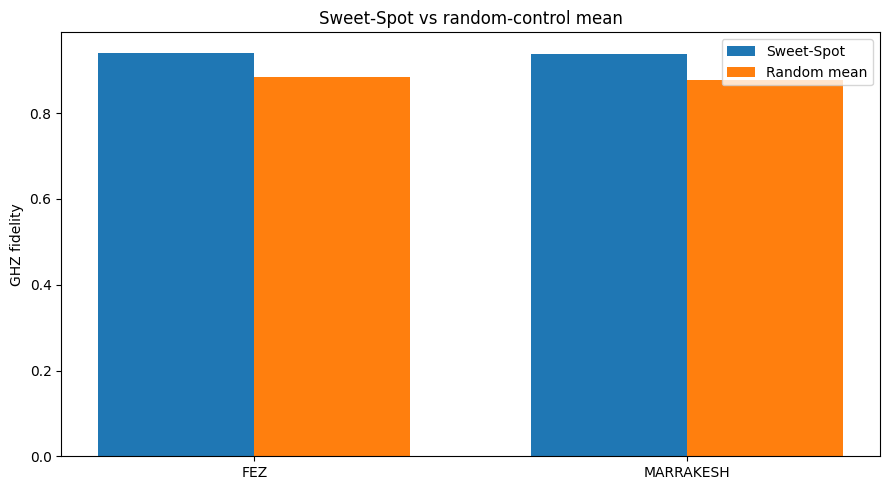

Saved: D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation\figures\01_sweet_spot_vs_random_mean.png


In [27]:

# Figure 1 — Sweet-Spot vs random mean
plt.figure(figsize=(9,5))
x = np.arange(len(backend_summary))
plt.bar(x - 0.18, backend_summary["sweet_fidelity"], width=0.36, label="Sweet-Spot")
plt.bar(x + 0.18, backend_summary["random_mean"], width=0.36, label="Random mean")
plt.xticks(x, backend_summary["backend"].str.replace("ibm_","").str.upper())
plt.ylabel("GHZ fidelity")
plt.title("Sweet-Spot vs random-control mean")
plt.legend()
savefig("01_sweet_spot_vs_random_mean.png")


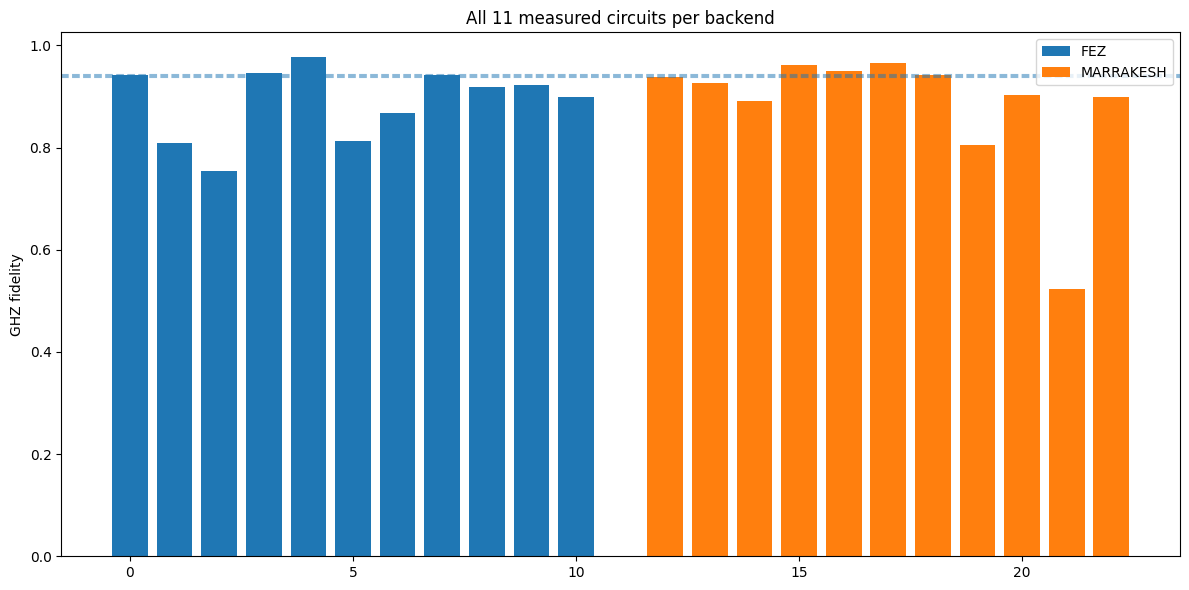

Saved: D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation\figures\02_all_circuit_fidelities.png


In [28]:

# Figure 2 — All primary circuit fidelities
plt.figure(figsize=(12,6))
for i, (backend, g) in enumerate(primary.groupby("backend")):
    vals = g.sort_values("circuit_index")
    x = np.arange(len(vals)) + i * 12
    plt.bar(x, vals["ghz_fidelity"], label=backend.replace("ibm_","").upper())
    sweet_idx = list(vals["is_sweet_spot"]).index(True)
    plt.axhline(vals["ghz_fidelity"].iloc[sweet_idx], linestyle="--", alpha=0.5)
plt.ylabel("GHZ fidelity")
plt.title("All 11 measured circuits per backend")
plt.legend()
savefig("02_all_circuit_fidelities.png")


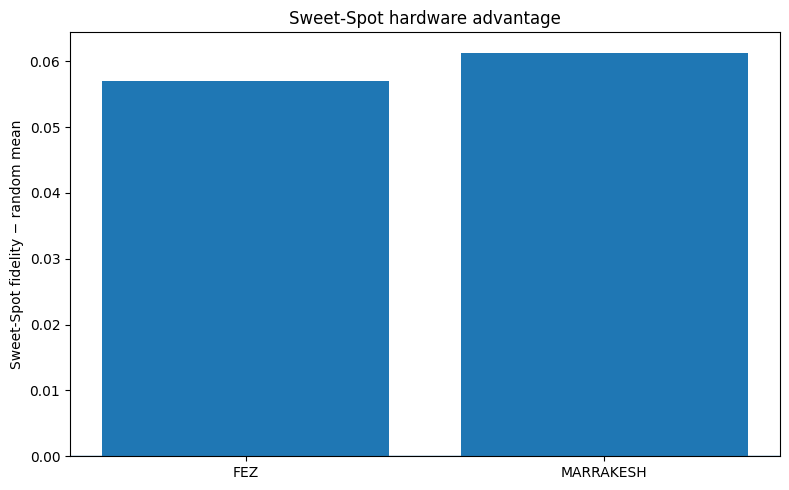

Saved: D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation\figures\03_backend_advantage.png


In [29]:

# Figure 3 — Backend-level advantage
plt.figure(figsize=(8,5))
plt.bar(
    backend_summary["backend"].str.replace("ibm_","").str.upper(),
    backend_summary["absolute_advantage"]
)
plt.axhline(0, linewidth=1)
plt.ylabel("Sweet-Spot fidelity − random mean")
plt.title("Sweet-Spot hardware advantage")
savefig("03_backend_advantage.png")


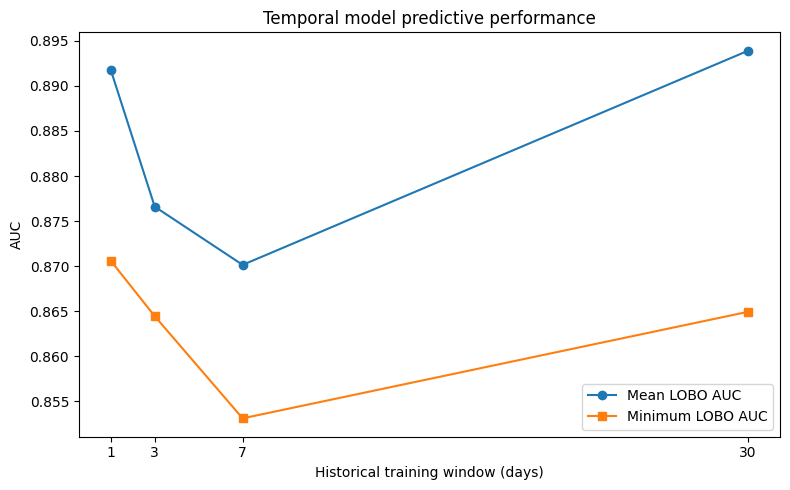

Saved: D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation\figures\04_temporal_auc.png


In [30]:

# Figure 4 — Temporal model AUC
plt.figure(figsize=(8,5))
tmp = model_compare.sort_values("window_days")
plt.plot(tmp["window_days"], tmp["lobo_mean_auc"], marker="o", label="Mean LOBO AUC")
plt.plot(tmp["window_days"], tmp["lobo_min_auc"], marker="s", label="Minimum LOBO AUC")
plt.xlabel("Historical training window (days)")
plt.ylabel("AUC")
plt.title("Temporal model predictive performance")
plt.xticks(tmp["window_days"])
plt.legend()
savefig("04_temporal_auc.png")


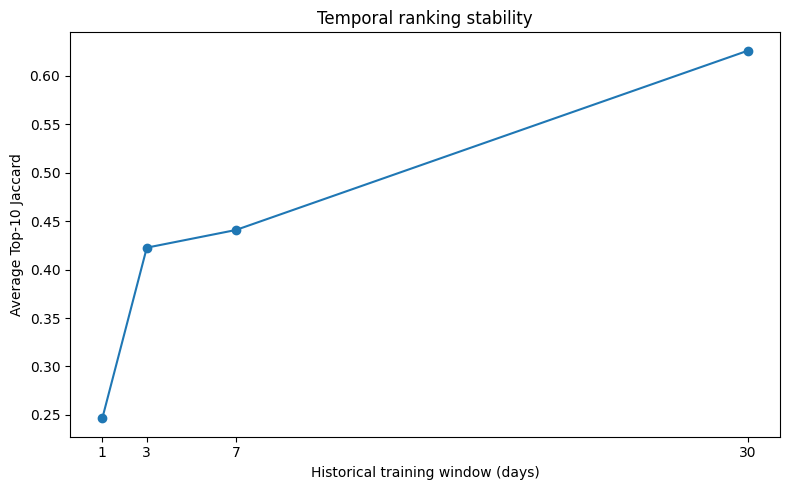

Saved: D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation\figures\05_temporal_ranking_stability.png


In [31]:

# Figure 5 — Ranking stability
plt.figure(figsize=(8,5))
plt.plot(
    model_compare.sort_values("window_days")["window_days"],
    model_compare.sort_values("window_days")["avg_top10_jaccard"],
    marker="o"
)
plt.xlabel("Historical training window (days)")
plt.ylabel("Average Top-10 Jaccard")
plt.title("Temporal ranking stability")
plt.xticks(model_compare["window_days"])
savefig("05_temporal_ranking_stability.png")


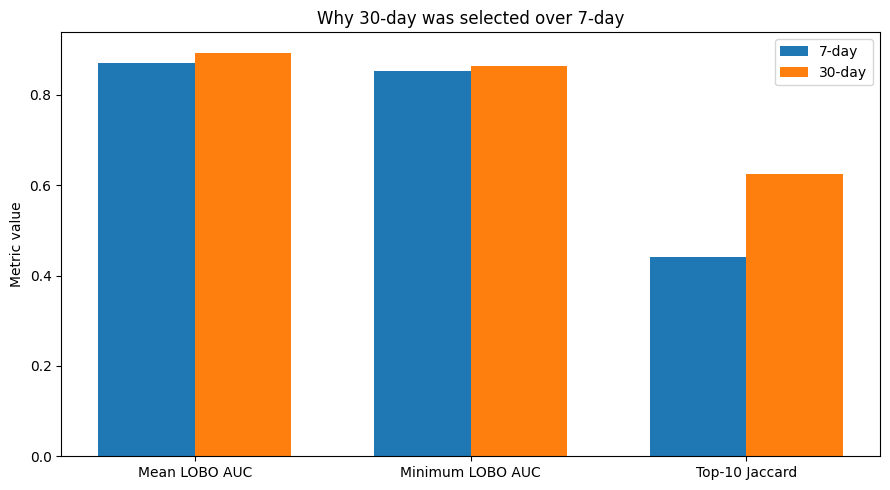

Saved: D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation\figures\06_7day_vs_30day.png


In [32]:

# Figure 6 — 7-day vs 30-day
fig, ax = plt.subplots(figsize=(9,5))
metrics = ["lobo_mean_auc","lobo_min_auc","avg_top10_jaccard"]
labels = ["Mean LOBO AUC","Minimum LOBO AUC","Top-10 Jaccard"]
x = np.arange(len(metrics))
w = 0.35
ax.bar(x-w/2, [m7[m] for m in metrics], width=w, label="7-day")
ax.bar(x+w/2, [m30[m] for m in metrics], width=w, label="30-day")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Metric value")
ax.set_title("Why 30-day was selected over 7-day")
ax.legend()
savefig("06_7day_vs_30day.png")


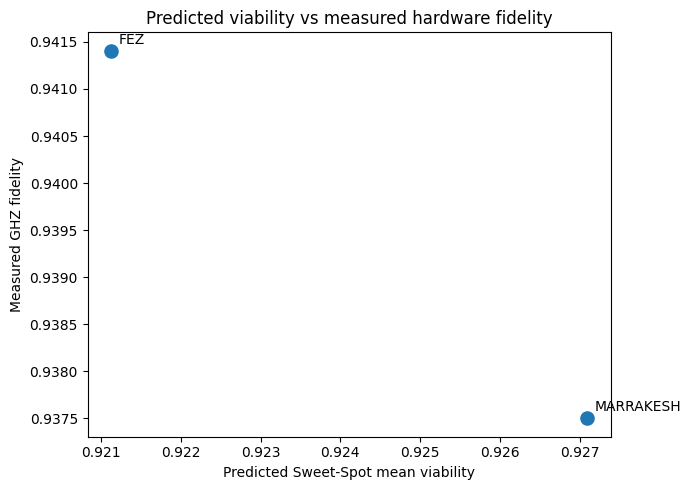

Saved: D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation\figures\07_viability_vs_hardware_fidelity.png


In [33]:

# Figure 7 — predicted viability vs measured Sweet-Spot fidelity
plt.figure(figsize=(7,5))
plt.scatter(
    pred_vs_hw["predicted_mean_viability"],
    pred_vs_hw["sweet_fidelity"],
    s=90
)
for _, r in pred_vs_hw.iterrows():
    plt.annotate(r["backend"].replace("ibm_","").upper(),
                 (r["predicted_mean_viability"], r["sweet_fidelity"]),
                 xytext=(5,5), textcoords="offset points")
plt.xlabel("Predicted Sweet-Spot mean viability")
plt.ylabel("Measured GHZ fidelity")
plt.title("Predicted viability vs measured hardware fidelity")
savefig("07_viability_vs_hardware_fidelity.png")


# 18. Export everything

All outputs are written to the **actual detected project root**, not `/mnt/data`.

Two locations are populated:

`ibm_circuits/sweet_spot_evaluation/`

and

`ibm_circuits/results/sweet_spot_evaluation/`

The root-level directory is intentional so it is immediately visible in the project explorer.


In [34]:

# ============================================================
# 26. EXPORT TABLES + JSON + TEXT CONCLUSION
# ============================================================
exports = {
    "hardware_all_loaded.csv": hardware,
    "hardware_primary.csv": primary,
    "kingston_replication.csv": replication,
    "backend_summary.csv": backend_summary,
    "circuit_ranking.csv": ranking,
    "shot_uncertainty.csv": shot_uncertainty,
    "empirical_control_test.csv": empirical_control_test,
    "depth_sensitivity.csv": depth_sensitivity,
    "same_depth_analysis.csv": same_depth_analysis,
    "temporal_model_comparison.csv": model_compare,
    "seven_vs_thirty_day.csv": seven_vs_thirty,
    "predicted_vs_hardware.csv": pred_vs_hw,
    "bootstrap_advantage.csv": bootstrap_advantage,
    "kingston_replication_summary.csv": kingston_replication_summary,
}

for name, data in exports.items():
    if isinstance(data, pd.DataFrame) and not data.empty:
        data.to_csv(EVAL_DIR / name, index=False)
        data.to_csv(RESULTS_EVAL_DIR / name, index=False)

summary_json = {
    "experiment": "Temporal 30-day Sweet-Spot vs topology-valid random controls",
    "prediction_date": PREDICTION_DATE,
    "shots_per_circuit": SHOTS,
    "circuits_per_backend": EXPECTED_CIRCUITS,
    "primary_jobs": primary_job,
    "kingston_replication_job": OLD_KINGSTON_JOB,
    "backend_summary": backend_summary.to_dict(orient="records"),
    "temporal_model_comparison": model_compare.to_dict(orient="records"),
    "seven_vs_thirty_day": seven_vs_thirty.to_dict(orient="records"),
    "verdict": VERDICT,
}

for target in [
    EVAL_DIR / "final_evaluation_summary.json",
    RESULTS_EVAL_DIR / "final_evaluation_summary.json",
]:
    target.write_text(json.dumps(summary_json, indent=2, default=str), encoding="utf-8")

for target in [
    EVAL_DIR / "FINAL_RESEARCH_CONCLUSION.txt",
    RESULTS_EVAL_DIR / "FINAL_RESEARCH_CONCLUSION.txt",
]:
    target.write_text(VERDICT + "\n", encoding="utf-8")

print("=" * 80)
print("EVALUATION COMPLETE")
print("ROOT OUTPUT :", EVAL_DIR)
print("RESULTS OUT :", RESULTS_EVAL_DIR)
print("=" * 80)

print("\nFiles:")
for p in sorted(EVAL_DIR.rglob("*")):
    if p.is_file():
        print(" ", p.relative_to(EVAL_DIR))


EVALUATION COMPLETE
ROOT OUTPUT : D:\Downloads\uday projects\ibm_circuits\sweet_spot_evaluation
RESULTS OUT : D:\Downloads\uday projects\ibm_circuits\results\sweet_spot_evaluation

Files:
  backend_summary.csv
  bootstrap_advantage.csv
  circuit_ranking.csv
  depth_sensitivity.csv
  empirical_control_test.csv
  figures\01_sweet_spot_vs_random_mean.png
  figures\02_all_circuit_fidelities.png
  figures\03_backend_advantage.png
  figures\04_temporal_auc.png
  figures\05_temporal_ranking_stability.png
  figures\06_7day_vs_30day.png
  figures\07_viability_vs_hardware_fidelity.png
  final_evaluation_summary.json
  FINAL_RESEARCH_CONCLUSION.txt
  hardware_all_loaded.csv
  hardware_primary.csv
  kingston_replication.csv
  kingston_replication_summary.csv
  predicted_vs_hardware.csv
  same_depth_analysis.csv
  seven_vs_thirty_day.csv
  shot_uncertainty.csv
  temporal_model_comparison.csv


# 19. Final interpretation guide

The final report should distinguish three questions:

### A. What is the Sweet-Spot?

A topology-valid physical 3-qubit chain selected **prospectively** by the Temporal 30-day model's predicted viability score.

### B. Did it beat random hardware controls?

Use the backend summary, rank, fraction of controls beaten, paired backend advantages, and same-depth sensitivity.

### C. Why 30-day rather than 7-day?

The 30-day model was selected because it had the best held-out LOBO AUC and the strongest ranking stability among the tested temporal windows. The 7-day model's training viable rate alone is not sufficient evidence of superiority.

### Scientific limitation

The experiment has three independent backends. The ten controls within a backend are repeated circuit selections on the same hardware and therefore should not be treated as ten independent hardware replications. The Kingston second run is a replication, not a fourth backend.

Also report the routing/depth confound because several random controls required deeper transpiled circuits.
